Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.metrics import*
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

SyntaxError: invalid syntax (_label.py, line 114)

Importing the dataset

In [193]:
df=pd.read_csv('https://raw.githubusercontent.com/mk-gurucharan/Regression/master/SampleData.csv')

In [194]:
df.head()

,Hours of Study,Marks
0,32.502345,31.707006
1,53.426804,68.777596
2,61.530358,62.562382
3,47.475640,71.546632
4,59.813208,87.230925


## Problem Statement :-

In this data, we have one independent variable(feature) "Hours of Study" and one dependent variable(target) "Marks"
Train a SVR model to understand the relationship between feature and target variables.
Predict the students' marks based on their no. of hours of study.

## Solution

Given Dataset

In [195]:
df.head()

,Hours of Study,Marks
0,32.502345,31.707006
1,53.426804,68.777596
2,61.530358,62.562382
3,47.475640,71.546632
4,59.813208,87.230925


In [196]:
df.tail()

,Hours of Study,Marks
95,50.030174,81.536991
96,49.239765,72.111832
97,50.039576,85.232007
98,48.149859,66.224958
99,25.128485,53.454394


EDA -> Exploratory Data Analysis

In [197]:
len(df)

100

In [198]:
df.isnull().sum()

Hours of Study    0
Marks             0
dtype: int64

In [199]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Hours of Study  100 non-null    float64
 1   Marks           100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


In [200]:
df.describe()

,Hours of Study,Marks
count,100.000000,100.000000
mean,48.958341,72.035051
std,9.746379,15.200087
min,25.128485,31.707006
25%,41.526164,60.788586
50%,49.634970,72.179542
75%,56.762631,83.215080
max,70.346076,99.051415


In [201]:
#Renaming the column
df.rename(columns={'Hours of Study':'Hours'},inplace=True)

<Axes: >

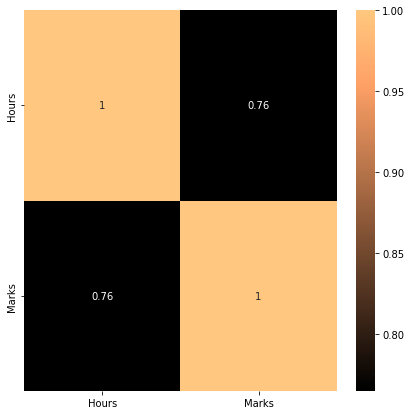

In [202]:
plt.figure(figsize=(7,7))
sns.heatmap(df.corr(),annot=True,cmap='copper')

Text(0.5, 1.0, 'Hours v/s Marks')

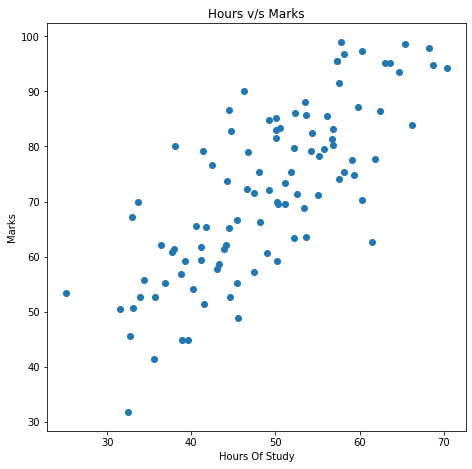

In [203]:
plt.figure(figsize=(7.5,7.5))
plt.scatter(df.Hours,df.Marks)
plt.xlabel("Hours Of Study")
plt.ylabel("Marks")
plt.title("Hours v/s Marks")

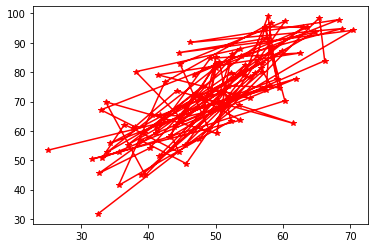

In [204]:
plt.plot(df.Hours,df.Marks,marker='*',color='red')
plt.plot()
plt.show()

Preprocessing Step

In [205]:
X=np.array(df.iloc[:,:-1]).reshape(-1,1)
Y=np.array(df.iloc[:,-1]).reshape(-1,1)

In [206]:
stanscale = StandardScaler()

In [240]:
X=stanscale.fit_transform(X.reshape(-1,1))
Y=stanscale.fit_transform(Y.reshape(-1,1))

Splitting the Data

In [241]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=10)

In [209]:
X_train.shape

(80, 1)

Defining the Model

In [210]:
model = SVR(kernel='rbf')

In [211]:
model.fit(X_train,Y_train)

c:\Users\arunk\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:1183: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

Predicting the Values

In [212]:
Y_pred=model.predict(X_test).reshape(-1,1)

In [213]:
Y_test

array([[-1.00224427],
       [ 0.62160848],
       [-0.70156137],
       [-1.40938966],
       [ 0.89018186],
       [-0.03229448],
       [-1.79768014],
       [-0.89032789],
       [-0.65528619],
       [-0.11790059],
       [-0.62633786],
       [-0.21538463],
       [-0.68441449],
       [-0.44658889],
       [ 0.62827334],
       [ 1.46933383],
       [ 1.50879256],
       [ 1.54854301],
       [-0.8381571 ],
       [-1.18692938]])

In [214]:
#Inverse standardization
Y_pred = stanscale.inverse_transform(Y_pred)

In [215]:
#Inverse standardization
Y_test=stanscale.inverse_transform(Y_test)

Predicted Values

In [216]:
Y_test

array([[56.87721319],
       [81.43619216],
       [61.4247098 ],
       [50.71958891],
       [85.49806778],
       [71.54663223],
       [44.84712424],
       [58.56982472],
       [62.12457082],
       [70.25193442],
       [62.5623823 ],
       [68.77759598],
       [61.68403752],
       [65.28088692],
       [81.53699078],
       [94.25710159],
       [94.85387123],
       [95.45505292],
       [59.35885025],
       [54.0840548 ]])

In [217]:
Y_pred

array([[60.39764577],
       [81.48677868],
       [66.49889641],
       [52.93601862],
       [80.71338315],
       [70.24215505],
       [60.59170512],
       [65.92240434],
       [56.96814488],
       [86.44247075],
       [88.27618157],
       [77.33308614],
       [63.51595177],
       [64.15643611],
       [73.17585776],
       [90.56964555],
       [92.26453877],
       [82.25831189],
       [63.41941707],
       [62.23679956]])

Text(0.5, 1.0, 'Actual Marks v/s Predicted Marks')

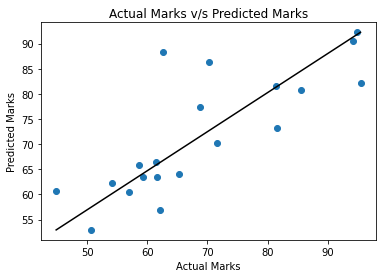

In [218]:
plt.scatter(Y_test,Y_pred)
plt.plot([Y_test.min(),Y_test.max()],[Y_pred.min(),Y_pred.max()],color='black')
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual Marks v/s Predicted Marks")

In [219]:
X_test=stanscale.inverse_transform(X_test).reshape(-1,1)

In [220]:
stanscale.inverse_transform(model.predict([[5]]).reshape(-1,1))

array([[71.50453478]])

In [221]:
stanscale.inverse_transform(model.predict([[50]]).reshape(-1,1))
#Model is flawed

array([[71.50346437]])

In [222]:
model.score(X_test,Y_test)

-22.201271634669343

In [223]:
r2_score(Y_test,Y_pred)

0.5943071038285547

In [224]:
mean_absolute_error(Y_test,Y_pred)

6.933427431006029

In [225]:
mean_squared_error(Y_test,Y_pred)

87.23306900235274

Using Linear Regression Model

In [226]:
model2=LinearRegression()

In [227]:
model2.fit(X_train,Y_train)

LinearRegression()

In [242]:
Y_pred2=model2.predict(X_test)

In [244]:
Y_pred2=stanscale.inverse_transform(Y_pred2)
Y_pred2

array([[-0.76260334],
       [ 0.67378576],
       [-0.35729581],
       [-1.22157906],
       [ 0.62592166],
       [-0.06817752],
       [-0.75153981],
       [-0.40159193],
       [-0.95354092],
       [ 0.95784987],
       [ 1.05899189],
       [ 0.40909782],
       [-0.57291761],
       [-0.52971779],
       [ 0.13669271],
       [ 1.76600051],
       [ 1.63925927],
       [ 0.72052516],
       [-0.57927984],
       [-0.65432863]])

In [245]:
Y_test

array([[-1.00224427],
       [ 0.62160848],
       [-0.70156137],
       [-1.40938966],
       [ 0.89018186],
       [-0.03229448],
       [-1.79768014],
       [-0.89032789],
       [-0.65528619],
       [-0.11790059],
       [-0.62633786],
       [-0.21538463],
       [-0.68441449],
       [-0.44658889],
       [ 0.62827334],
       [ 1.46933383],
       [ 1.50879256],
       [ 1.54854301],
       [-0.8381571 ],
       [-1.18692938]])

In [231]:
Y_test=stanscale.inverse_transform(Y_test)

In [246]:
r2_score(Y_test,Y_pred2)

0.6012408249667436

In [250]:
stanscale.inverse_transform(mean_absolute_error(Y_test,Y_pred2).reshape(-1,1))

array([[0.45377835]])